In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [49]:
from plotting_ts_tools import (
    calculate_anomaly,
    calculate_anomaly_timeslice,
    line_plot,
    line_plot_min_max,
    select_index,
    cleanup,
    adjust_names,
    adjust_length,
    line_plot_anomaly,
    box_plot_anomaly,
    lineplot_and_boxplot,
    load_era5_csv,
    load_rcms_csv
)

In [437]:
# Select Variables
#
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#climate_index='R20mm' 
#climate_index= 'DD'
#climate_index= 'TG'
#climate_index='SU40'
#climate_index='TR26'
climate_index='RRm'

var_meta = select_index(climate_index)
print(var_meta)
# select country and time step
#
#country='Togo'
#country='Burkina Faso'
country='Ivory Coast'
timestep='year'


{'longname': 'mean precipitation [mm/day]', 'unit_base': 'mm/day', 'description': 'Mean precipitation'}


In [438]:
# Load the CSV file containing the data for the selected index, country, and time step:
#
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+climate_index
file_name='climdexCORDEX_AFR22_'+climate_index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [439]:
# Load csv file for ERA5
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5/'+climate_index
file_name='climdexERA5_'+climate_index+'_'+timestep+'_weighted_means.csv'
era5_path = os.path.join(path,file_name)
era5data = pd.read_csv(era5_path)

In [440]:
var_meta

{'longname': 'mean precipitation [mm/day]',
 'unit_base': 'mm/day',
 'description': 'Mean precipitation'}

In [441]:
# define output path and filename
#
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v3/'+climate_index
#outfile = os.path.join(outputpath,climate_index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [442]:
# The data needs to be cut to the same length for all scenarios and the same time period for all indices.
# cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
# For TG, we need to load the data with longnameK to convert from K to °C in the load function. 
# For the other indices, we can load the data without longnameK.
#

if climate_index == 'TG':
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31', longnameK=var_meta['longnameK'])
else:
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31')

Data after cleanup: 
23        AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
78        AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
133       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
188       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
243       AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...
                                ...                        
135433    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135488    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135543    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135598    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
135653    AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC...
Name: realization, Length: 2467, dtype: object
23                   MOHC-HadGEM2-ES
78                   MOHC-HadGEM2-ES
133                  MOHC-HadGEM2-ES
188                  MOHC-HadGEM2-ES
243                  MOHC-HadGEM2-ES
                     ...            
135433    NCC-NorESM1-MNCC-NorESM1-M
135488    NCC

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/TIMESERIES/plotting_ts_tools.py:458: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  #        raise ValueError("Could not parse year values in CORDEX AFR-22 CSV.")


In [443]:
cut_data.columns

Index(['realization', 'year', 'region', 'mean precipitation [mm/year]',
       'ci_name', 'ci_frequency', 'standard_name', 'units', 'GCM', 'RCM',
       'scenario'],
      dtype='object')

In [444]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
if climate_index == "RRm":
    var_meta['longname'] = var_meta['longname'].replace('mm/day', 'mm/year')

print(var_meta['longname'])    
df_anomaly_year = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', var_meta['longname'])
#df.head()

mean precipitation [mm/year]


In [445]:
# Mean anomaly per time slice, for each realization and scenario
# Use pre-defined `slices` if available; otherwise fall back to standard ranges
slices_to_use = [
        ("2031-2060", 2031, 2060),
        ("2069-2098", 2069, 2098),
    ]
anom_slice_means = calculate_anomaly_timeslice(df_anomaly_year, slices_to_use)
anom_slice_means.head()

,slice,region,standard_name,realization,scenario,anomaly_mean,years
0,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp26,-11.095215,30
1,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp85,-49.506907,30
2,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp26,-85.311309,30
3,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp85,-142.221408,30
4,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_NCC-NorESM...,rcp26,-243.239561,30


In [446]:
var_meta['longname']

'mean precipitation [mm/year]'

In [447]:
df_anomaly_year.columns

Index(['realization', 'year', 'region', 'mean precipitation [mm/year]',
       'ci_name', 'ci_frequency', 'standard_name', 'units', 'GCM', 'RCM',
       'scenario', 'mean_ref', 'anomaly', 'running_mean_10yr',
       'running_mean_30yr', 'year_running_mean_10yr',
       'year_running_mean_30yr'],
      dtype='object')

In [448]:
# Chose:
# make line plot with or without ERA5
# anomaly or running_mean_10yr or running_mean_30yr

#line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'model', country, climate_index, longname)
#line_plot_anomaly(df_anomaly_year, 'year', 'running_mean_10yr', outputpath, 'model', country, climate_index,var_meta['longname'])
#line_plot_anomaly(df_anomaly_year, 'year', 'running_mean_30yr', outputpath, 'model', country, climate_index,var_meta['longname'])
#line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'scenario_min_max', country, climate_index, var_meta['longname'])
#line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'scenario_min_max', country, climate_index, var_meta['longname'], era5=df_era5_anomalie)

file liegt:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v3/RRm/line_plot_test.png


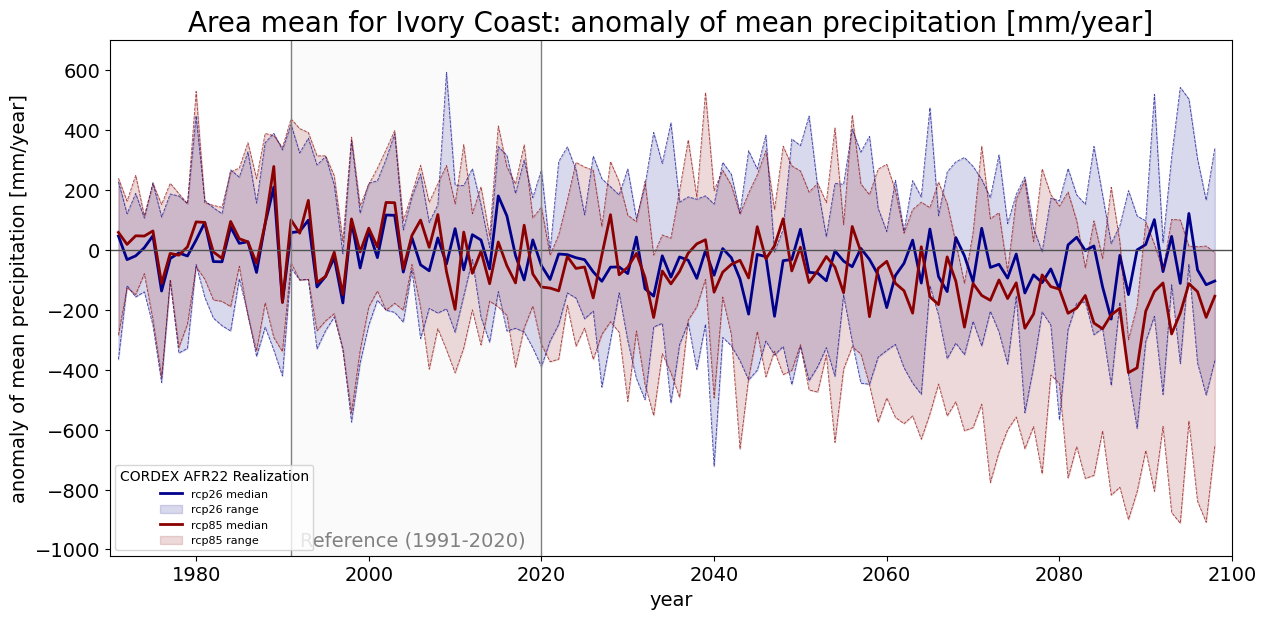

In [449]:
line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'scenario_min_max', country, climate_index, var_meta['longname'])

Saving figure to /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v3/RRm/RRm_Ivory_Coast_timeseries_box_minmax_p15p85_oT.png


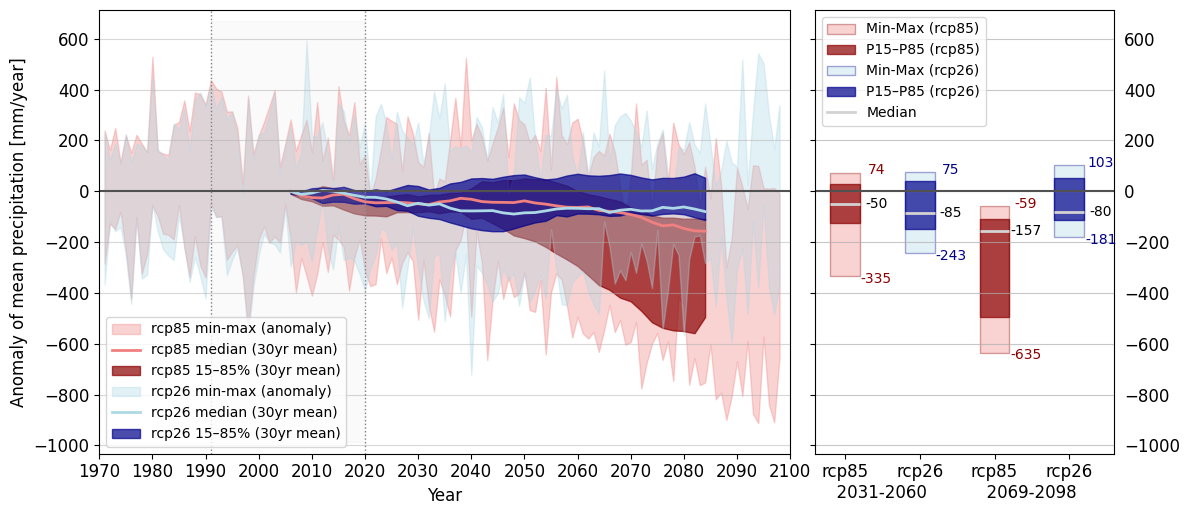

In [450]:
# now line plot with era5 and box plot beside each other in one figure:
# Increased label font sizes
#removed ERA5 for now outof the plotting function.
lineplot_and_boxplot(df_anomaly_year,anom_slice_means, country, climate_index, var_meta['longname'], outputpath)